# Oracle-Vidur: Current System Characterization & Bottleneck Diagnostics

This notebook characterizes the **currently running system** (`BaselineEvictionSim` in [`sim/baseline_sim.py`](../sim/baseline_sim.py), built on `PinSim` + `Sim`) using [`InstrumentedBaselineSim`](../sim/diagnostics.py) (zero behavioral drift — verified for exact parity below).

## System Policy & Execution Configuration
| Component | Current Setting | Details |
| :--- | :--- | :--- |
| **Eviction Policy** | **`LRU`** (`"lru"`) & **`FIFO`** (`"fifo"`) | `LRU` picks the idle session with oldest `parked_at`; `FIFO` picks earliest `arrival`. Both are evaluated and labeled in every figure. |
| **Proactive Reloading** | **`OFF` (`False` — Reactive On-Demand Only)** | Evicted KV caches NEVER start transferring over PCIe H2D before `tool_done` fires. 100% of reloads are on-demand after the tool returns. |
| **Proactive / Slack Eviction** | **`OFF` (`False` — Reactive Pressure Eviction Only)** | Evictions ONLY run inside `_admit_full()` or `_prepare_decode_growth()` when HBM free blocks run short (`free < needed + headroom`). There is no slack filter yet. |
| **Resident Admission Check** | **Incremental Growth Only (`fixed`)** | [`BaselineEvictionSim._admit_full`](../sim/baseline_sim.py#L122-L137) requests only incremental blocks (`blocks_for_tokens(target) - len(vllm_block_ids)`) when resident, or full `target_blocks` when evicted. |
| **Eviction Candidate Pool** | `St.TOOL` **and** `St.WAITING` | Any non-running session with pinned HBM blocks is evictable — including sessions already in `St.WAITING`. |
| **Hardware Model** | LLaMA-3-8B KV + H100 PCIe | `128 KiB/token` (`2.0 MiB` per 16-tok block); calibrated H100 step model & PCIe (`D2H = 46.78 GB/s`, `H2D = 45.49 GB/s`). |

### How a Tool-Wait & Return Works in the Current System
```text
PREFILL / DECODE  ──►  Tool call starts  ──►  St.TOOL (KV blocks kept pinned in GPU HBM)
                                                 │
         ┌───────────────────────────────────────┴───────────────────────────────────────┐
         ▼ Resident (Not evicted during tool wait)                                       ▼ Evicted (Forced offload via PCIe D2H -> offloaded_dram)
   tool_done fires                                                                 tool_done fires
         │                                                                               │
         ▼                                                                               ▼
   Enters St.WAITING                                                          Submits ON-DEMAND PCIe H2D reload (No proactive reload!)
   (NO _reconcile() call -> waits for next 0.5s epoch tick!)                       ──► Enters St.STALL for queue_wait + H2D_tx seconds
         │                                                                               │
         ▼                                                                               ▼
   _vllm_reconcile() -> _admit_full()                                              reload_done fires -> Enters St.WAITING -> immediate _reconcile()
   Checks ONLY incremental blocks beyond pinned KV (`blocks(target) - held`)             │
         │                                                                               ▼
         ▼                                                                         _admit_full() checks free HBM for entire context + new tokens
   Allocates incremental blocks (evicts if needed) or stays in St.WAITING          Allocates blocks (calling _force_unpin if needed) or waits in St.WAITING
```

### The 5 Questions Answered Here
1. **HBM Space for New Tool Tokens:** How many returning tool calls lack enough KV space for the new tool tokens $k$ (and pass-generated tokens $g$), and therefore trigger evictions?
2. **Total & Per-Return Evictions:** How many total evictions occur during each run, what triggers them, and what is the average number of evictions per returning tool call?
3. **Eviction Safety:** How many of those evictions target **safe** ($\Delta t \ge T_{\text{RTT}}$) vs. **unsafe** entries (and why)?
4. **PCIe Bus Reload Wait (On-Demand):** How many evicted KV reloads face PCIe H2D bus queueing vs. serialization wait, and what is the average wait time?
5. **Reload HBM Availability & Wait Time:** Of the reloads finishing PCIe H2D, how many immediately have HBM space to load vs. need to wait in `St.WAITING`, and how long do the waiting ones wait?

In [1]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

cwd = Path.cwd()
if not (cwd / "data" / "swebench_traces.jsonl").exists() and (cwd.parent / "data" / "swebench_traces.jsonl").exists():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sim.scheduler_sim import KVGeometry, CostModel, PCIeLink, poisson_arrivals
from sim.verify_evictions import load_openhands_traces
from sim.baseline_sim import BaselineEvictionSim
from sim.diagnostics import InstrumentedBaselineSim

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11.5,
    "axes.labelsize": 10.5,
    "legend.fontsize": 9.0,
    "xtick.labelsize": 9.2,
    "ytick.labelsize": 9.2,
})

traces = load_openhands_traces("data/swebench_traces.jsonl")
geom = KVGeometry(layers=32)  # 32 layers, 8 KV heads, 128 dim, FP16 -> 128 KiB/token, 2 MiB/block
cost_model = CostModel.from_calibration("results/sim_costmodel_h100_0905b.json")
link_ref = PCIeLink.from_calibration("results/sim_calibration.json")
d2h_bw = link_ref.d2h_gbytes_per_sec or link_ref.gbytes_per_sec
h2d_bw = link_ref.h2d_gbytes_per_sec or link_ref.gbytes_per_sec

print(f"Working dir:   {PROJECT_ROOT}")
print(f"Dataset:       {len(traces)} SWE-bench traces (7,977 tool-wait turns total)")
print(f"KV Geometry:   {geom.bytes_per_token // 1024} KiB/token | {geom.bytes_per_block // (1024**2):.0f} MiB/block ({geom.block_tokens} tokens/block)")
print(f"Calibrated H100 PCIe: D2H = {d2h_bw:.2f} GB/s | H2D = {h2d_bw:.2f} GB/s")
print(f"Default Mode:  Eviction Policy = LRU / FIFO | Proactive Reload = False (On-Demand Only)")

# Inspect peak single-trajectory size in the seed=42 sample used by verify_evictions.py
rng = random.Random(42)
sample20 = [rng.choice(traces) for _ in range(20)]
peak_gbs = sorted(
    (geom.blocks_for_tokens(max(it.ctx_tokens for it in tr.iters)) * geom.bytes_per_block / (1024**3), tr.req_id, len(tr.iters))
    for tr in sample20
)
oversized_8g = [x for x in peak_gbs if x[0] > 8.0]
print(f"\nSeed=42 20-request sample: median peak KV = {np.median([x[0] for x in peak_gbs]):.2f} GB | max = {peak_gbs[-1][0]:.2f} GB ({peak_gbs[-1][1]})")
print(f"Requests in this sample exceeding 8 GB HBM ALONE ({len(oversized_8g)}/20): " + ", ".join(f"{r} ({g:.2f} GB)" for g, r, _ in oversized_8g))

Working dir:   /Users/javierdiegof/Documents/uiuc/semester_3/Hardware and Software for AI/project/oracle-vidur
Dataset:       300 SWE-bench traces (7,977 tool-wait turns total)
KV Geometry:   128 KiB/token | 2 MiB/block (16 tokens/block)
Calibrated H100 PCIe: D2H = 46.78 GB/s | H2D = 45.49 GB/s
Default Mode:  Eviction Policy = LRU / FIFO | Proactive Reload = False (On-Demand Only)

Seed=42 20-request sample: median peak KV = 4.48 GB | max = 24.41 GB (sphinx-doc__sphinx-10451)
Requests in this sample exceeding 8 GB HBM ALONE (4/20): sympy__sympy-15346 (10.77 GB), sympy__sympy-15346 (10.77 GB), django__django-13448 (11.07 GB), sphinx-doc__sphinx-10451 (24.41 GB)


## 1. Running Existing Check-Tests (`verify_evictions.py`) & Fixed-Rate Sweeps

All 5 verification configurations run with **`BaselineEvictionSim` exact semantics** (`n_requests=20`, `seed=42`, `max_time=1000.0s`):
- **Eviction policy:** `LRU` (`32G λ=0.05`, `16G λ=0.10`, `12G λ=0.15`, `8G λ=0.20`) and `FIFO` (`8G λ=0.20`)
- **Proactive reloading:** `False` (On-Demand reload only)

In [2]:
def run_instrumented(kv_hbm_gb: float, rate: float, policy: str,
                     n_requests: int = 20, seed: int = 42, max_time: float = 1000.0):
    rng = random.Random(seed)
    sampled_traces = [rng.choice(traces) for _ in range(n_requests)]
    arrival_times = poisson_arrivals(n_requests, rate=rate, seed=seed)
    link = PCIeLink.from_calibration("results/sim_calibration.json")

    sim = InstrumentedBaselineSim(
        traces=sampled_traces,
        arrival_times=arrival_times,
        eviction_policy=policy,
        kv_hbm_gb=kv_hbm_gb,
        geom=geom,
        cost=cost_model,
        link=link,
    )
    sim.run(max_time=max_time)
    m = sim.summary_metrics()
    m["rate"] = rate
    m["label"] = f"{policy.upper()} {kv_hbm_gb:.0f}G\n(λ={rate:.2f}, NoProact)"
    m["short_label"] = f"{policy.upper()} {kv_hbm_gb:.0f}G\nλ={rate:.2f}"
    return sim, m

verify_configs = [
    (32.0, 0.05, "lru"),
    (16.0, 0.10, "lru"),
    (12.0, 0.15, "lru"),
    (8.0,  0.20, "lru"),
    (8.0,  0.20, "fifo"),
]

verify_runs = [run_instrumented(hbm, r, pol) for hbm, r, pol in verify_configs]

# Exact parity & accounting conservation verification
rng = random.Random(42)
_st = [rng.choice(traces) for _ in range(20)]
_arr = poisson_arrivals(20, rate=0.10, seed=42)
_base16 = BaselineEvictionSim(_st, _arr, eviction_policy="lru", kv_hbm_gb=16.0, geom=geom, cost=cost_model,
                              link=PCIeLink.from_calibration("results/sim_calibration.json"))
_base16.run(max_time=1000.0)
_ins16, _m16 = verify_runs[1]
assert _base16.total_evictions == _ins16.total_evictions
assert _base16.total_evicted_bytes == _ins16.total_evicted_bytes
assert _base16.total_reloads == _ins16.total_reloads
assert abs(_base16.now - _ins16.now) < 1e-12
for _, m in verify_runs:
    assert sum(m["evictions_by_trigger"].values()) == m["total_evictions"]
    assert m["reload_fit_immediately_count"] + m["reload_waited_for_hbm_count"] + m["reload_still_in_pcie_at_end"] == m["evicted_returns"]
print("Parity vs BaselineEvictionSim & trigger/reload conservation checks: PASSED (100% exact match).")

print("\nSystem Configuration & Completion Overview:")
hdr = f"{'Config':<17} | {'Policy':<6} | {'ProactiveReload':<15} | {'Done':<5} | {'Returns':<7} | {'Evictions':<9} | {'Reloads':<7}"
print("=" * len(hdr))
print(hdr)
print("-" * len(hdr))
for _, m in verify_runs:
    print(f"{m['kv_hbm_gb']:>4.0f}G λ={m['rate']:<4.2f}      | {m['policy'].upper():<6} | {str(m['proactive_reload']):<15} | "
          f"{m['done_requests']:>2}/{m['total_requests']:<2} | {m['total_tool_returns']:>7d} | {m['total_evictions']:>9d} | {m['evicted_returns']:>7d}")
print("=" * len(hdr))

Parity vs BaselineEvictionSim & trigger/reload conservation checks: PASSED (100% exact match).

System Configuration & Completion Overview:
Config            | Policy | ProactiveReload | Done  | Returns | Evictions | Reloads
------------------------------------------------------------------------------------
  32G λ=0.05      | LRU    | False           | 14/20 |     387 |       143 |     137
  16G λ=0.10      | LRU    | False           | 12/20 |     330 |       169 |     162
  12G λ=0.15      | LRU    | False           |  9/20 |     296 |       175 |     162
   8G λ=0.20      | LRU    | False           |  9/20 |     229 |       130 |     122
   8G λ=0.20      | FIFO   | False           |  9/20 |     229 |       130 |     122


## 2. Q1: How Many Tool-Call Returns Lack KV Space for New Tokens ($k$ / $k+g$) & Call for Evictions?

When a tool call finishes and starts the next LLM turn (`k = new_tool_tokens`, `g = pass_gen_tokens` generated by the pass itself):
- **If Resident (KV stayed pinned in HBM):** [`BaselineEvictionSim._admit_full`](../sim/baseline_sim.py#L122-L137) now checks only incremental blocks beyond already-pinned HBM pages (`blocks_for_tokens(target) - len(lv.vllm_block_ids) + headroom`).
- **If Evicted (KV in DRAM):** it holds `0` blocks in HBM, so it needs blocks for its entire reloaded context + new tokens.
- **Why some resident returns that fit at `tool_done` still contend later (`Contended by Epoch`):** `tool_done` for a resident return sets `St.WAITING` *without* calling `_reconcile()`. During the up-to-`0.5s` wait until the next `epoch` tick (or ahead in FCFS), active decodes and `reload_done` admissions consume free blocks, so free HBM can shrink below incremental need by the time `_admit_full` actually runs. *(Note: in OpenHands traces `it.ctx_tokens` already bundles $k+g$ and decode steps increment `gpu_cached_tokens` on top, so simulator `held_blocks` can slightly differ by a block between raw $k$ and $k+g$ checks.)*

Config (NoProact)  | All Ret | PhysNoHBM(k) | PhysNoHBM(k+g) | CalledEvict(Admit) | Res NoK -> TrigEv | Evicted NoHBM
---------------------------------------------------------------------------------------------------------------------
LRU 32G λ=0.05     |     387 | 128/387 (33%) |  129/387 (33%) |      114/387 (29%) |  12/250 -> 32/250 | 117/137 (85%)
LRU 16G λ=0.10     |     330 | 144/330 (44%) |  143/330 (43%) |      124/330 (38%) |  12/168 -> 32/168 | 132/162 (81%)
LRU 12G λ=0.15     |     296 | 148/296 (50%) |  148/296 (50%) |      125/296 (42%) |  10/134 -> 27/134 | 138/162 (85%)
LRU 8G λ=0.20      |     229 | 114/229 (50%) |  113/229 (49%) |       90/229 (39%) |   7/107 -> 17/107 | 107/122 (88%)
FIFO 8G λ=0.20     |     229 | 114/229 (50%) |  113/229 (49%) |       90/229 (39%) |   7/107 -> 17/107 | 107/122 (88%)


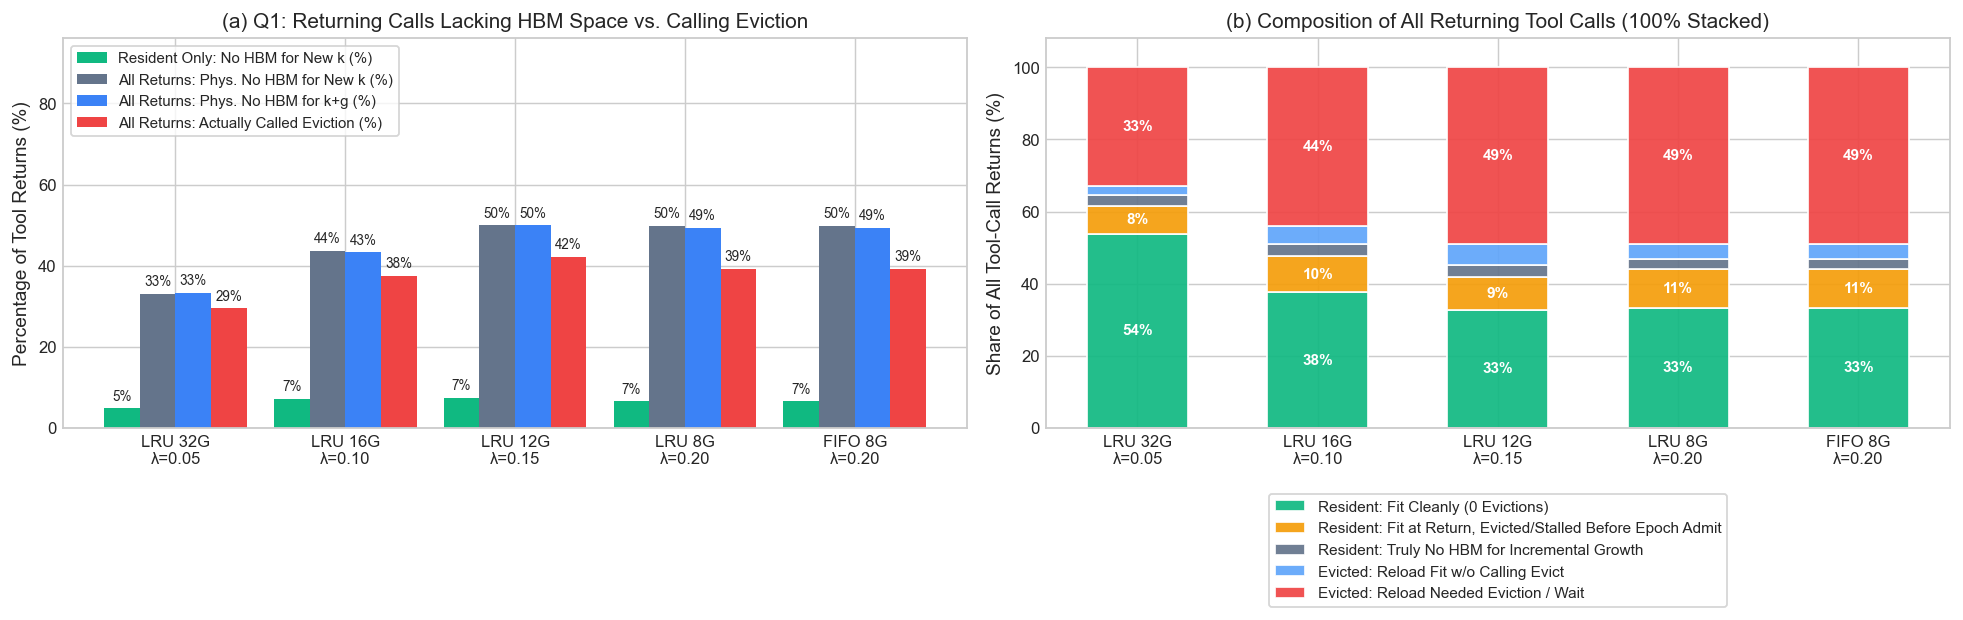

In [3]:
x = np.arange(len(verify_runs))
labels = [m["short_label"] for _, m in verify_runs]

hdr = (
    f"{'Config (NoProact)':<18} | {'All Ret':<7} | {'PhysNoHBM(k)':<12} | {'PhysNoHBM(k+g)':<14} | "
    f"{'CalledEvict(Admit)':<18} | {'Res NoK -> TrigEv':<17} | {'Evicted NoHBM':<13}"
)
print(hdr)
print("-" * len(hdr))
for _, m in verify_runs:
    tot = m["total_tool_returns"]
    res = m["resident_returns"]
    evr = m["evicted_returns"]
    cfg = f"{m['policy'].upper()} {m['kv_hbm_gb']:.0f}G λ={m['rate']:.2f}"
    pk = f"{m['all_returns_no_hbm_for_k_at_tool_done']}/{tot} ({100*m['all_returns_no_hbm_for_k_at_tool_done']/tot:.0f}%)"
    pkg = f"{m['all_returns_no_hbm_for_kg_at_tool_done']}/{tot} ({100*m['all_returns_no_hbm_for_kg_at_tool_done']/tot:.0f}%)"
    ca = f"{m['all_returns_triggered_admit_evict']}/{tot} ({100*m['all_returns_triggered_admit_evict']/tot:.0f}%)"
    res_s = f"{m['resident_no_hbm_for_k_at_tool_done']}/{res} -> {m['resident_triggered_admit_evict']}/{res}"
    evs = f"{m['evicted_no_hbm_at_tool_done']}/{evr} ({100*m['evicted_no_hbm_at_tool_done']/max(1,evr):.0f}%)"
    print(f"{cfg:<18} | {tot:>7d} | {pk:>12} | {pkg:>14} | {ca:>18} | {res_s:>17} | {evs:>13}")

fig, axes = plt.subplots(1, 2, figsize=(15.2, 5.0))

# Panel A: Physical Shortage (k vs k+g) vs Actual Eviction Calls (All Tool Returns)
p_k = [100.0 * m["all_returns_no_hbm_for_k_at_tool_done"] / max(1, m["total_tool_returns"]) for _, m in verify_runs]
p_kg = [100.0 * m["all_returns_no_hbm_for_kg_at_tool_done"] / max(1, m["total_tool_returns"]) for _, m in verify_runs]
act_admit = [100.0 * m["all_returns_triggered_admit_evict"] / max(1, m["total_tool_returns"]) for _, m in verify_runs]
res_k = [100.0 * m["resident_no_hbm_for_k_at_tool_done"] / max(1, m["resident_returns"]) for _, m in verify_runs]

w = 0.21
axes[0].bar(x - 1.5*w, res_k, w, label="Resident Only: No HBM for New k (%)", color="#10b981")
axes[0].bar(x - 0.5*w, p_k, w, label="All Returns: Phys. No HBM for New k (%)", color="#64748b")
axes[0].bar(x + 0.5*w, p_kg, w, label="All Returns: Phys. No HBM for k+g (%)", color="#3b82f6")
axes[0].bar(x + 1.5*w, act_admit, w, label="All Returns: Actually Called Eviction (%)", color="#ef4444")
for xi, a, b, c, d in zip(x, res_k, p_k, p_kg, act_admit):
    axes[0].text(xi - 1.5*w, a + 1.2, f"{a:.0f}%", ha="center", va="bottom", fontsize=7.5)
    axes[0].text(xi - 0.5*w, b + 1.2, f"{b:.0f}%", ha="center", va="bottom", fontsize=7.5)
    axes[0].text(xi + 0.5*w, c + 1.2, f"{c:.0f}%", ha="center", va="bottom", fontsize=7.5)
    axes[0].text(xi + 1.5*w, d + 1.2, f"{d:.0f}%", ha="center", va="bottom", fontsize=7.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 96)
axes[0].set_ylabel("Percentage of Tool Returns (%)")
axes[0].set_title("(a) Q1: Returning Calls Lacking HBM Space vs. Calling Eviction")
axes[0].legend(loc="upper left", frameon=True, fontsize=8.3)

# Panel B: Resident vs Evicted Breakdown of ALL Returning Calls
res_clean_pct, res_later_pct, res_short_pct, ev_clean_pct, ev_need_pct = [], [], [], [], []
for sim, m in verify_runs:
    tot = max(1, m["total_tool_returns"])
    res = [r for r in sim.return_events if not r["was_evicted"]]
    evr = [r for r in sim.return_events if r["was_evicted"]]
    n_res_short = sum(1 for r in res if not r["has_hbm_space_at_tool_done_raw"])
    n_res_later = sum(1 for r in res if r["has_hbm_space_at_tool_done_raw"] and (r["admit_evictions_triggered"] > 0 or r["failed_due_to_hbm_at_attempt"] or r["evicted_while_waiting"]))
    n_res_clean = len(res) - n_res_short - n_res_later
    n_ev_clean = sum(1 for r in evr if r["has_hbm_space_at_tool_done_raw"] and r["admit_evictions_triggered"] == 0)
    n_ev_need = len(evr) - n_ev_clean
    res_clean_pct.append(100.0 * n_res_clean / tot)
    res_later_pct.append(100.0 * n_res_later / tot)
    res_short_pct.append(100.0 * n_res_short / tot)
    ev_clean_pct.append(100.0 * n_ev_clean / tot)
    ev_need_pct.append(100.0 * n_ev_need / tot)

stack_data = [
    ("Resident: Fit Cleanly (0 Evictions)", res_clean_pct, "#10b981"),
    ("Resident: Fit at Return, Evicted/Stalled Before Epoch Admit", res_later_pct, "#f59e0b"),
    ("Resident: Truly No HBM for Incremental Growth", res_short_pct, "#64748b"),
    ("Evicted: Reload Fit w/o Calling Evict", ev_clean_pct, "#60a5fa"),
    ("Evicted: Reload Needed Eviction / Wait", ev_need_pct, "#ef4444"),
]
bottom = np.zeros(len(verify_runs))
for lbl, vals, col in stack_data:
    arr = np.array(vals)
    axes[1].bar(x, arr, width=0.56, bottom=bottom, label=lbl, color=col, alpha=0.92, edgecolor="white")
    for xi, v, b in zip(x, arr, bottom):
        if v >= 7.0:
            axes[1].text(xi, b + v / 2.0, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    bottom += arr
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0, 108)
axes[1].set_ylabel("Share of All Tool-Call Returns (%)")
axes[1].set_title("(b) Composition of All Returning Tool Calls (100% Stacked)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=True, fontsize=8.5)

plt.tight_layout()
plt.show()

## 3. Q2: Total Evictions & Average Evictions Needed per Returning Tool Call

Notice that in whole-conversation eviction (`BaselineEvictionSim`), **evicting just 1 parked session frees hundreds to thousands of blocks (~2–6 GB)**, whereas a returning call's new tokens $k$ typically need far fewer blocks (median `k = 334` tokens $\approx 21$ blocks). Below we show exact causal attribution for every eviction triggered in the run, alongside per-return averages.

Config (NoProact)  | TotalEvict | AdmitRetEv | AdmitRetRes | AdmitNew | DecodeGrow | AvgAdmit/Ret | AvgWhenTrig | TotEv/TotRet
------------------------------------------------------------------------------------------------------------------------------
LRU 32G λ=0.05     |        143 |        105 |          36 |        0 |          1 |         0.36 |        1.23 |         0.37
LRU 16G λ=0.10     |        169 |        129 |          34 |        0 |          2 |         0.49 |        1.31 |         0.51
LRU 12G λ=0.15     |        175 |        137 |          33 |        1 |          2 |         0.57 |        1.38 |         0.59
LRU 8G λ=0.20      |        130 |        103 |          22 |        0 |          0 |         0.55 |        1.39 |         0.57
FIFO 8G λ=0.20     |        130 |        103 |          22 |        0 |          0 |         0.55 |        1.39 |         0.57


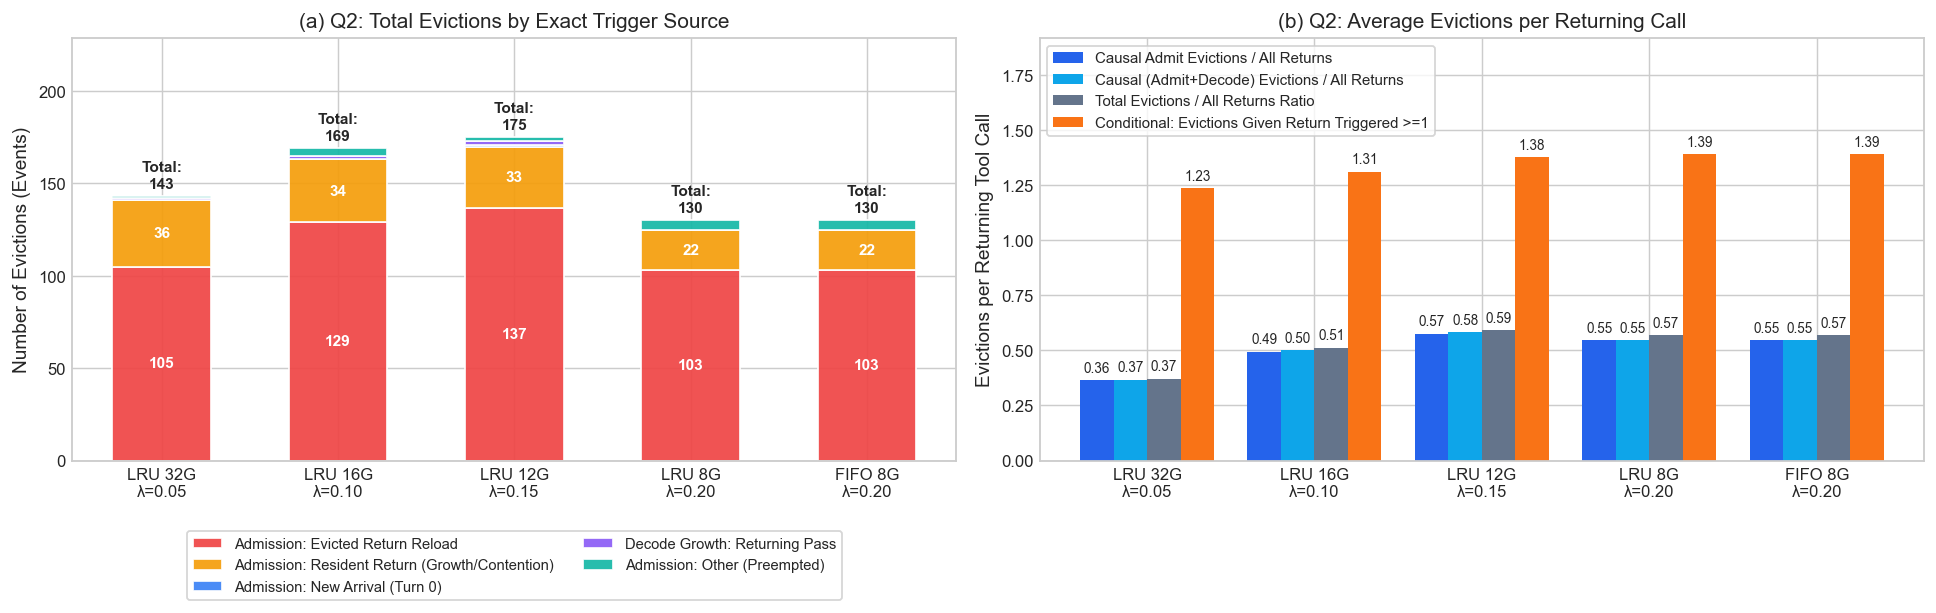

In [4]:
hdr = (
    f"{'Config (NoProact)':<18} | {'TotalEvict':<10} | {'AdmitRetEv':<10} | {'AdmitRetRes':<11} | "
    f"{'AdmitNew':<8} | {'DecodeGrow':<10} | {'AvgAdmit/Ret':<12} | {'AvgWhenTrig':<11} | {'TotEv/TotRet':<12}"
)
print(hdr)
print("-" * len(hdr))
for _, m in verify_runs:
    tr = m["evictions_by_trigger"]
    cfg = f"{m['policy'].upper()} {m['kv_hbm_gb']:.0f}G λ={m['rate']:.2f}"
    dec_g = tr.get("decode_growth_ret", 0) + tr.get("decode_growth_new", 0)
    print(f"{cfg:<18} | {m['total_evictions']:>10d} | {tr.get('admission_ret_evicted', 0):>10d} | "
          f"{tr.get('admission_ret_resident', 0):>11d} | {tr.get('admission_new', 0):>8d} | {dec_g:>10d} | "
          f"{m['avg_admit_evictions_per_return']:>12.2f} | {m['avg_evictions_when_return_triggers']:>11.2f} | "
          f"{m['overall_evictions_per_return_ratio']:>12.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.9))

# Panel A: Total Evictions by Causal Trigger
trig_defs = [
    ("admission_ret_evicted", "Admission: Evicted Return Reload", "#ef4444"),
    ("admission_ret_resident", "Admission: Resident Return (Growth/Contention)", "#f59e0b"),
    ("admission_new", "Admission: New Arrival (Turn 0)", "#3b82f6"),
    ("decode_growth_ret", "Decode Growth: Returning Pass", "#8b5cf6"),
    ("decode_growth_new", "Decode Growth: Initial Pass (Turn 0)", "#a855f7"),
    ("reconcile_stalled", "Reconcile Idle-GPU Force Unpin", "#64748b"),
    ("admission_other", "Admission: Other (Preempted)", "#14b8a6"),
]
bottom = np.zeros(len(verify_runs))
for key, lbl, col in trig_defs:
    vals = np.array([m["evictions_by_trigger"].get(key, 0) for _, m in verify_runs], dtype=float)
    if vals.sum() == 0:
        continue
    axes[0].bar(x, vals, width=0.56, bottom=bottom, label=lbl, color=col, alpha=0.92, edgecolor="white")
    for xi, v, b in zip(x, vals, bottom):
        if v >= 12:
            axes[0].text(xi, b + v / 2.0, f"{int(v)}", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    bottom += vals
for xi, tot in zip(x, bottom):
    axes[0].text(xi, tot + 3, f"Total:\n{int(tot)}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, max(bottom) * 1.25 + 10)
axes[0].set_ylabel("Number of Evictions (Events)")
axes[0].set_title("(a) Q2: Total Evictions by Exact Trigger Source")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True, fontsize=8.2)

# Panel B: Average Evictions per Returning Call
avg_adm = [m["avg_admit_evictions_per_return"] for _, m in verify_runs]
avg_pass = [m["avg_pass_evictions_per_return"] for _, m in verify_runs]
avg_tot_ratio = [m["overall_evictions_per_return_ratio"] for _, m in verify_runs]
avg_cond = [m["avg_evictions_when_return_triggers"] for _, m in verify_runs]

w2 = 0.20
axes[1].bar(x - 1.5*w2, avg_adm, w2, label="Causal Admit Evictions / All Returns", color="#2563eb")
axes[1].bar(x - 0.5*w2, avg_pass, w2, label="Causal (Admit+Decode) Evictions / All Returns", color="#0ea5e9")
axes[1].bar(x + 0.5*w2, avg_tot_ratio, w2, label="Total Evictions / All Returns Ratio", color="#64748b")
axes[1].bar(x + 1.5*w2, avg_cond, w2, label="Conditional: Evictions Given Return Triggered >=1", color="#f97316")
for xi, a, b, c, d in zip(x, avg_adm, avg_pass, avg_tot_ratio, avg_cond):
    axes[1].text(xi - 1.5*w2, a + 0.025, f"{a:.2f}", ha="center", va="bottom", fontsize=7.5)
    axes[1].text(xi - 0.5*w2, b + 0.025, f"{b:.2f}", ha="center", va="bottom", fontsize=7.5)
    axes[1].text(xi + 0.5*w2, c + 0.025, f"{c:.2f}", ha="center", va="bottom", fontsize=7.5)
    axes[1].text(xi + 1.5*w2, d + 0.025, f"{d:.2f}", ha="center", va="bottom", fontsize=7.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0, max(avg_cond + avg_tot_ratio) * 1.38)
axes[1].set_ylabel("Evictions per Returning Tool Call")
axes[1].set_title("(b) Q2: Average Evictions per Returning Call")
axes[1].legend(loc="upper left", frameon=True, fontsize=8.3)

plt.tight_layout()
plt.show()

## 4. Q3: How Many of Those Evictions Are Safe vs. Unsafe?

Every eviction triggered in [`_force_unpin`](../sim/baseline_sim.py#L78-L96) is evaluated at the instant of eviction:
- **Safe:** remaining `tool_time` $\Delta t \ge T_{\text{RTT}}$ (`T_d2h + T_h2d`), further split into **Queue-Aware Safe** ($\Delta t \ge W_{\text{D2H}} + T_{\text{RTT}}$) vs. **Ideal Safe Broken by D2H Queue**.
- **Unsafe:** $\Delta t < T_{\text{RTT}}$, broken down into:
  - **Already `St.WAITING` ($\Delta t = 0$):** the session's tool had *already finished*, yet `BaselineEvictionSim._force_unpin` allowed it as an eviction candidate and LRU picked it because its `parked_at` timestamp was oldest! *(And because `tool_done` already fired, it leaks into `offloaded_dram` without a reload event!)*
  - **Unsafe `St.TOOL` (Preventable vs. Unavoidable):** tool was still active with $\Delta t < T_{\text{RTT}}$.

Config (NoProact)  | Evict | Safe          | Unsafe        | AlreadyStWAIT | Safe(TOOL only) | AvgCand (1-cand%)
----------------------------------------------------------------------------------------------------------------
LRU 32G λ=0.05     |   143 |  37 (25.9%)   | 106 (74.1%)   |  75 (52.4%)   |  37/68  (54.4%) | 1.03 (96.5%)
LRU 16G λ=0.10     |   169 |  46 (27.2%)   | 123 (72.8%)   |  85 (50.3%)   |  46/84  (54.8%) | 1.11 (90.5%)
LRU 12G λ=0.15     |   175 |  43 (24.6%)   | 132 (75.4%)   | 102 (58.3%)   |  43/73  (58.9%) | 1.10 (93.1%)
LRU 8G λ=0.20      |   130 |  36 (27.7%)   |  94 (72.3%)   |  76 (58.5%)   |  36/54  (66.7%) | 1.08 (93.8%)
FIFO 8G λ=0.20     |   130 |  36 (27.7%)   |  94 (72.3%)   |  76 (58.5%)   |  36/54  (66.7%) | 1.08 (93.8%)


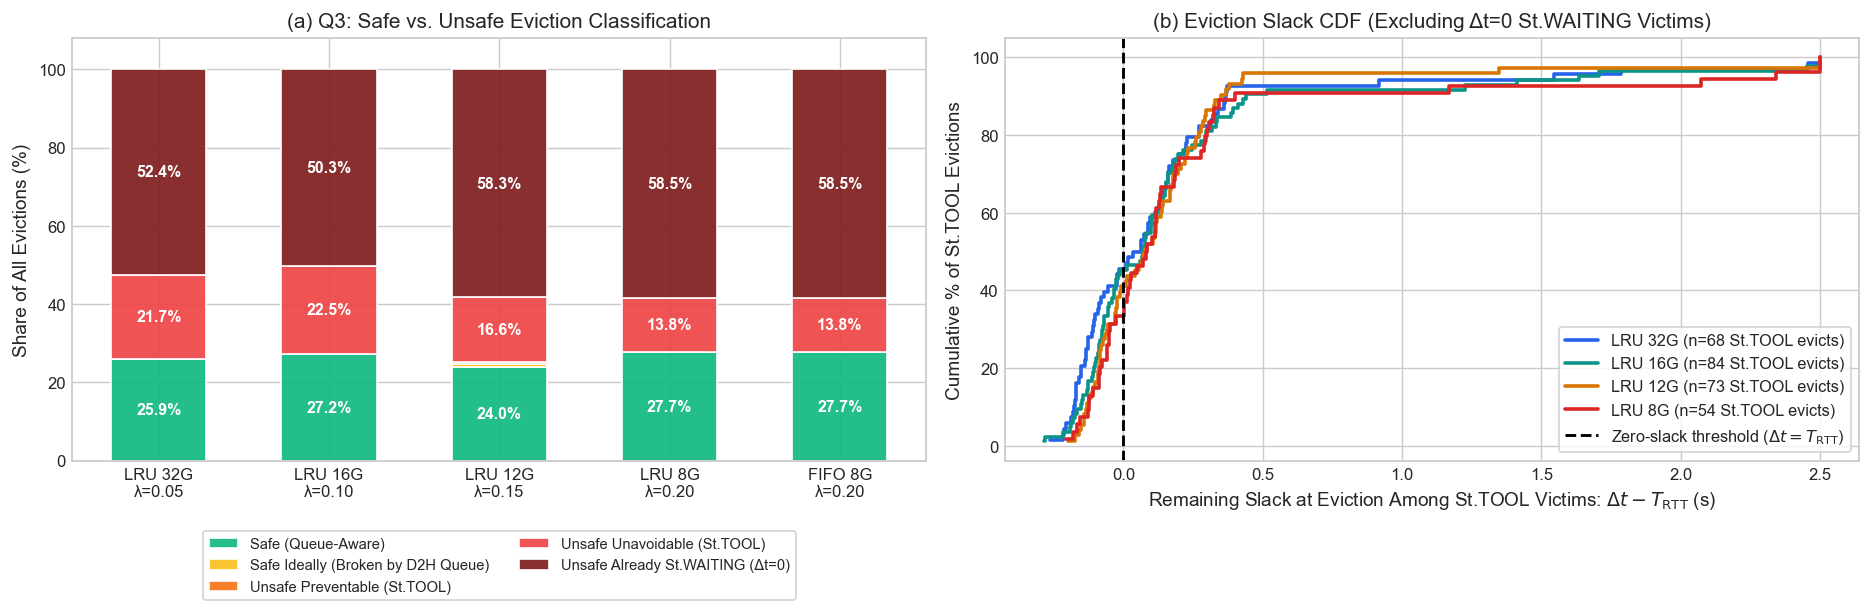

In [5]:
hdr = (
    f"{'Config (NoProact)':<18} | {'Evict':<5} | {'Safe':<13} | {'Unsafe':<13} | "
    f"{'AlreadyStWAIT':<13} | {'Safe(TOOL only)':<15} | {'AvgCand (1-cand%)'}"
)
print(hdr)
print("-" * len(hdr))
for _, m in verify_runs:
    cfg = f"{m['policy'].upper()} {m['kv_hbm_gb']:.0f}G λ={m['rate']:.2f}"
    sf = f"{m['safe_ideal_count']:>3d} ({m['safe_ideal_pct']:4.1f}%)"
    us = f"{m['unsafe_ideal_count']:>3d} ({m['unsafe_ideal_pct']:4.1f}%)"
    wt = f"{m['evicted_while_waiting_count']:>3d} ({100*m['evicted_while_waiting_count']/max(1,m['total_evictions']):4.1f}%)"
    st = f"{m['safe_ideal_count']:>3d}/{m['tool_only_evictions']:<3d} ({m['safe_pct_among_tool_victims']:4.1f}%)"
    cd = f"{m['avg_candidates_per_eviction']:.2f} ({m['single_candidate_eviction_pct']:.1f}%)"
    print(f"{cfg:<18} | {m['total_evictions']:>5d} | {sf:<13} | {us:<13} | {wt:<13} | {st:<15} | {cd}")

cats = {
    "Safe (Queue-Aware)": [],
    "Safe Ideally (Broken by D2H Queue)": [],
    "Unsafe Preventable (St.TOOL)": [],
    "Unsafe Unavoidable (St.TOOL)": [],
    "Unsafe Already St.WAITING (Δt=0)": [],
}
for sim, m in verify_runs:
    evs = sim.eviction_events
    n = max(1, len(evs))
    cats["Safe (Queue-Aware)"].append(100.0 * sum(1 for e in evs if e["is_safe_d2h_queue"]) / n)
    cats["Safe Ideally (Broken by D2H Queue)"].append(100.0 * sum(1 for e in evs if e["is_safe_ideal"] and not e["is_safe_d2h_queue"]) / n)
    cats["Unsafe Preventable (St.TOOL)"].append(100.0 * sum(1 for e in evs if e["victim_state"] == "tool" and e["preventable_unsafe_ideal"]) / n)
    cats["Unsafe Unavoidable (St.TOOL)"].append(100.0 * sum(1 for e in evs if e["victim_state"] == "tool" and (not e["is_safe_ideal"]) and (not e["any_safe_candidate_ideal"])) / n)
    cats["Unsafe Already St.WAITING (Δt=0)"].append(100.0 * sum(1 for e in evs if e["victim_state"] == "waiting") / n)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.9))
colors = ["#10b981", "#fbbf24", "#f97316", "#ef4444", "#7f1d1d"]
bottom = np.zeros(len(verify_runs))
for (name, vals), col in zip(cats.items(), colors):
    arr = np.array(vals)
    axes[0].bar(x, arr, width=0.56, bottom=bottom, label=name, color=col, alpha=0.92, edgecolor="white")
    for xi, v, b in zip(x, arr, bottom):
        if v >= 7.0:
            axes[0].text(xi, b + v / 2.0, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=8.8, fontweight="bold")
    bottom += arr
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 108)
axes[0].set_ylabel("Share of All Evictions (%)")
axes[0].set_title("(a) Q3: Safe vs. Unsafe Eviction Classification")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True, fontsize=8.2)

# Panel B: Dataset feasibility scatter vs victim slack CDF
for (sim, m), col in zip(verify_runs[:4], ["#2563eb", "#0d9488", "#d97706", "#dc2626"]):
    tool_slacks = sorted(e["slack_ideal_s"] for e in sim.eviction_events if e["victim_state"] == "tool")
    if tool_slacks:
        cdf = np.arange(1, len(tool_slacks) + 1) / len(tool_slacks) * 100.0
        axes[1].step(np.clip(tool_slacks, -0.4, 2.5), cdf, where="post", lw=2.0, color=col,
                     label=f"{m['policy'].upper()} {m['kv_hbm_gb']:.0f}G (n={len(tool_slacks)} St.TOOL evicts)")
axes[1].axvline(0.0, color="black", linestyle="--", lw=1.6, label=r"Zero-slack threshold ($\Delta t = T_{\mathrm{RTT}}$)")
axes[1].set_xlabel(r"Remaining Slack at Eviction Among St.TOOL Victims: $\Delta t - T_{\mathrm{RTT}}$ (s)")
axes[1].set_ylabel("Cumulative % of St.TOOL Evictions")
axes[1].set_title("(b) Eviction Slack CDF (Excluding Δt=0 St.WAITING Victims)")
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

## 5. Q4: How Many Evicted KV Reloads Face PCIe Bus Wait & What Is the Average Wait Time?

Remember: **Proactive Reload = `False` (`On-Demand Reload Only`)**.
So **every single evicted KV cache reload (100%)** must block on PCIe H2D when `tool_done` fires for `H2D_queue_wait + H2D_transfer_tx` seconds. We report both:
1. **PCIe H2D Queue Contention Wait** (`queue_wait > 0`): reloads delayed waiting in the PCIe H2D FIFO behind *another* transfer (showing **both** conditional average *when queued* and unconditional average across all reloads).
2. **Total On-Demand PCIe Stall (`queue_wait + H2D_transfer_tx`)**: full PCIe duration spent stalled before HBM admission can run.
3. **D2H Offload Races:** how often `tool_done` fired *before* the evicted cache finished draining to host DRAM (`offload_finish > tool_done`).

Config (NoProact)  | Reloads | Queued on PCIe H2D | Avg Q (Queued) | Avg Q (All) | Max Q    | Avg H2D TX | Avg Tot PCIe | D2H Unfin
-----------------------------------------------------------------------------------------------------------------------------------
LRU 32G λ=0.05     |     137 |  3/137 ( 2.2%)     |        61.5 ms |      1.3 ms |    85 ms |    62.2 ms |      63.6 ms |  8 (5.8%)
LRU 16G λ=0.10     |     162 |  7/162 ( 4.3%)     |        67.5 ms |      2.9 ms |   143 ms |    62.8 ms |      65.7 ms |  9 (5.6%)
LRU 12G λ=0.15     |     162 |  8/162 ( 4.9%)     |        57.7 ms |      2.8 ms |    97 ms |    58.9 ms |      61.7 ms |  7 (4.3%)
LRU 8G λ=0.20      |     122 |  4/122 ( 3.3%)     |        19.9 ms |      0.7 ms |    41 ms |    57.6 ms |      58.2 ms |  2 (1.6%)
FIFO 8G λ=0.20     |     122 |  4/122 ( 3.3%)     |        19.9 ms |      0.7 ms |    41 ms |    57.6 ms |      58.2 ms |  2 (1.6%)


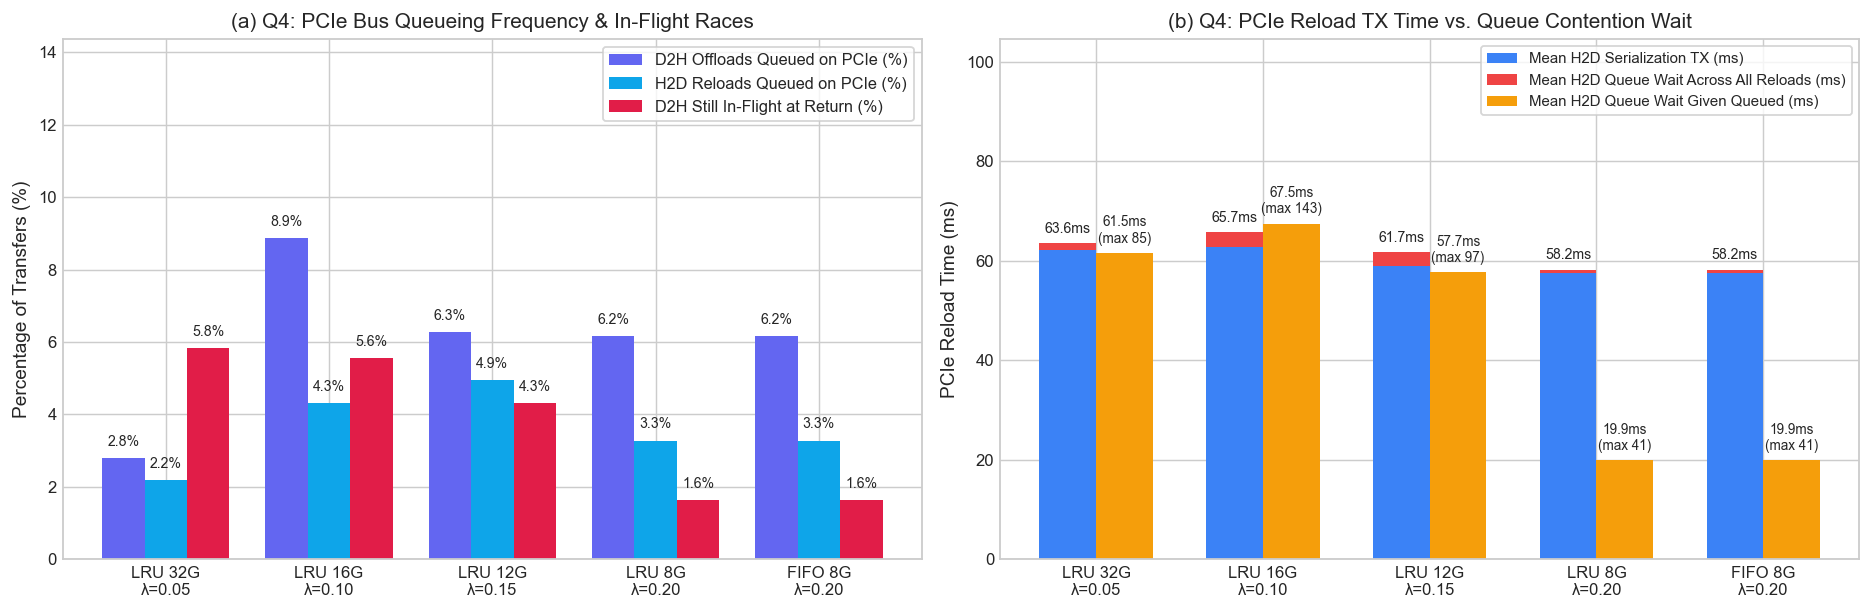

In [6]:
hdr = (
    f"{'Config (NoProact)':<18} | {'Reloads':<7} | {'Queued on PCIe H2D':<18} | {'Avg Q (Queued)':<14} | "
    f"{'Avg Q (All)':<11} | {'Max Q':<8} | {'Avg H2D TX':<10} | {'Avg Tot PCIe':<12} | {'D2H Unfin'}"
)
print(hdr)
print("-" * len(hdr))
for _, m in verify_runs:
    cfg = f"{m['policy'].upper()} {m['kv_hbm_gb']:.0f}G λ={m['rate']:.2f}"
    q_str = f"{m['h2d_queue_waited_count']:>2d}/{m['evicted_returns']:<3d} ({m['h2d_queue_waited_pct_of_reloads']:4.1f}%)"
    print(f"{cfg:<18} | {m['evicted_returns']:>7d} | {q_str:<18} | "
          f"{m['mean_h2d_queue_wait_when_queued_s']*1000:>11.1f} ms | "
          f"{m['mean_h2d_queue_wait_s']*1000:>8.1f} ms | "
          f"{m['max_h2d_queue_wait_s']*1000:>5.0f} ms | "
          f"{m['mean_h2d_tx_s']*1000:>7.1f} ms | "
          f"{m['mean_h2d_total_pcie_wait_s']*1000:>9.1f} ms | "
          f"{m['offload_unfinished_at_return']:>2d} ({100*m['offload_unfinished_at_return']/max(1,m['evicted_returns']):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))

# Panel A: PCIe Queueing Rates & D2H Races
d2h_q_pct = [m["d2h_bus_waited_pct"] for _, m in verify_runs]
h2d_q_pct = [m["h2d_queue_waited_pct_of_reloads"] for _, m in verify_runs]
d2h_unfin_pct = [100.0 * m["offload_unfinished_at_return"] / max(1, m["evicted_returns"]) for _, m in verify_runs]

w = 0.26
axes[0].bar(x - w, d2h_q_pct, w, label="D2H Offloads Queued on PCIe (%)", color="#6366f1")
axes[0].bar(x,     h2d_q_pct, w, label="H2D Reloads Queued on PCIe (%)", color="#0ea5e9")
axes[0].bar(x + w, d2h_unfin_pct, w, label="D2H Still In-Flight at Return (%)", color="#e11d48")
for xi, a, b, c in zip(x, d2h_q_pct, h2d_q_pct, d2h_unfin_pct):
    axes[0].text(xi - w, a + 0.25, f"{a:.1f}%", ha="center", va="bottom", fontsize=7.8)
    axes[0].text(xi,     b + 0.25, f"{b:.1f}%", ha="center", va="bottom", fontsize=7.8)
    axes[0].text(xi + w, c + 0.25, f"{c:.1f}%", ha="center", va="bottom", fontsize=7.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, max(d2h_q_pct + h2d_q_pct + d2h_unfin_pct) * 1.45 + 1.5)
axes[0].set_ylabel("Percentage of Transfers (%)")
axes[0].set_title("(a) Q4: PCIe Bus Queueing Frequency & In-Flight Races")
axes[0].legend(loc="upper right", frameon=True)

# Panel B: H2D PCIe Wait Breakdown (TX + Queue Wait All + Conditional Queue Wait When Queued)
tx_ms = [m["mean_h2d_tx_s"] * 1000 for _, m in verify_runs]
qw_all_ms = [m["mean_h2d_queue_wait_s"] * 1000 for _, m in verify_runs]
qw_cond_ms = [m["mean_h2d_queue_wait_when_queued_s"] * 1000 for _, m in verify_runs]
max_qw_ms = [m["max_h2d_queue_wait_s"] * 1000 for _, m in verify_runs]

w2 = 0.34
axes[1].bar(x - w2/2, tx_ms, w2, label="Mean H2D Serialization TX (ms)", color="#3b82f6")
axes[1].bar(x - w2/2, qw_all_ms, w2, bottom=tx_ms, label="Mean H2D Queue Wait Across All Reloads (ms)", color="#ef4444")
axes[1].bar(x + w2/2, qw_cond_ms, w2, label="Mean H2D Queue Wait Given Queued (ms)", color="#f59e0b")
for xi, t, qa, qc, mq in zip(x, tx_ms, qw_all_ms, qw_cond_ms, max_qw_ms):
    axes[1].text(xi - w2/2, t + qa + 1.5, f"{t+qa:.1f}ms", ha="center", va="bottom", fontsize=7.8)
    axes[1].text(xi + w2/2, qc + 1.5, f"{qc:.1f}ms\n(max {mq:.0f})", ha="center", va="bottom", fontsize=7.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0, max(max(t+qa for t, qa in zip(tx_ms, qw_all_ms)), max(qw_cond_ms)) * 1.55)
axes[1].set_ylabel("PCIe Reload Time (ms)")
axes[1].set_title("(b) Q4: PCIe Reload TX Time vs. Queue Contention Wait")
axes[1].legend(loc="upper right", frameon=True, fontsize=8.3)

plt.tight_layout()
plt.show()

## 6. Q5: Of the Reloads, How Many Have Enough HBM Space Immediately vs. Need to Wait (and How Long)?

When an on-demand H2D reload completes (`reload_done` fires), [`BaselineEvictionSim._handle`](../sim/baseline_sim.py#L171-L175) immediately sets `St.WAITING` and calls `_reconcile()`. Three things can happen right then:
1. **Immediate Fit with Raw Free HBM (`0.0s` HBM wait, `0` evictions needed):** enough free blocks existed without evicting anyone and FCFS wasn't blocked.
2. **Immediate Fit *Only After Evicting Another Idle Request* (`0.0s` HBM wait):** raw free HBM wasn't enough, so `_admit_full` immediately evicted parked `St.TOOL`/`St.WAITING` victim(s) to make room.
3. **Had to Wait in `St.WAITING` (`> 0s` HBM wait):** even after evicting idle sessions (or because an earlier FCFS head couldn't fit), there was not enough HBM — so the reload stalled waiting for GPU work to finish *(or remained stuck in `St.WAITING` when `max_time=1000s` closed, especially when single oversized requests exceeded `kv_hbm_gb`)*.

Config (NoProact)  | ReloadDone | Fit RawFree | Fit AfterEv | WaitedHBM     | WaitMean(Adm) | WaitP50(Adm) | WaitMax(Adm) | WaitMean(All+Cens)
----------------------------------------------------------------------------------------------------------------------------------------------
LRU 32G λ=0.05     |        137 |           1 |          35 | 101 (73.7%)   |       11.97 s |       4.87 s |      222.4 s |       11.97 s (0 open)
LRU 16G λ=0.10     |        160 |           4 |          33 | 123 (76.9%)   |       20.92 s |       5.75 s |      288.4 s |       20.92 s (0 open)
LRU 12G λ=0.15     |        162 |           3 |          25 | 134 (82.7%)   |       18.95 s |       5.92 s |      344.1 s |       26.42 s (7 open)
LRU 8G λ=0.20      |        122 |           0 |          18 | 104 (85.2%)   |       25.14 s |       6.56 s |      323.2 s |       29.33 s (5 open)
FIFO 8G λ=0.20     |        122 |           0 |          18 | 104 (85.2%)   |       25.14 s |       6.56 s |      323.2 s |   

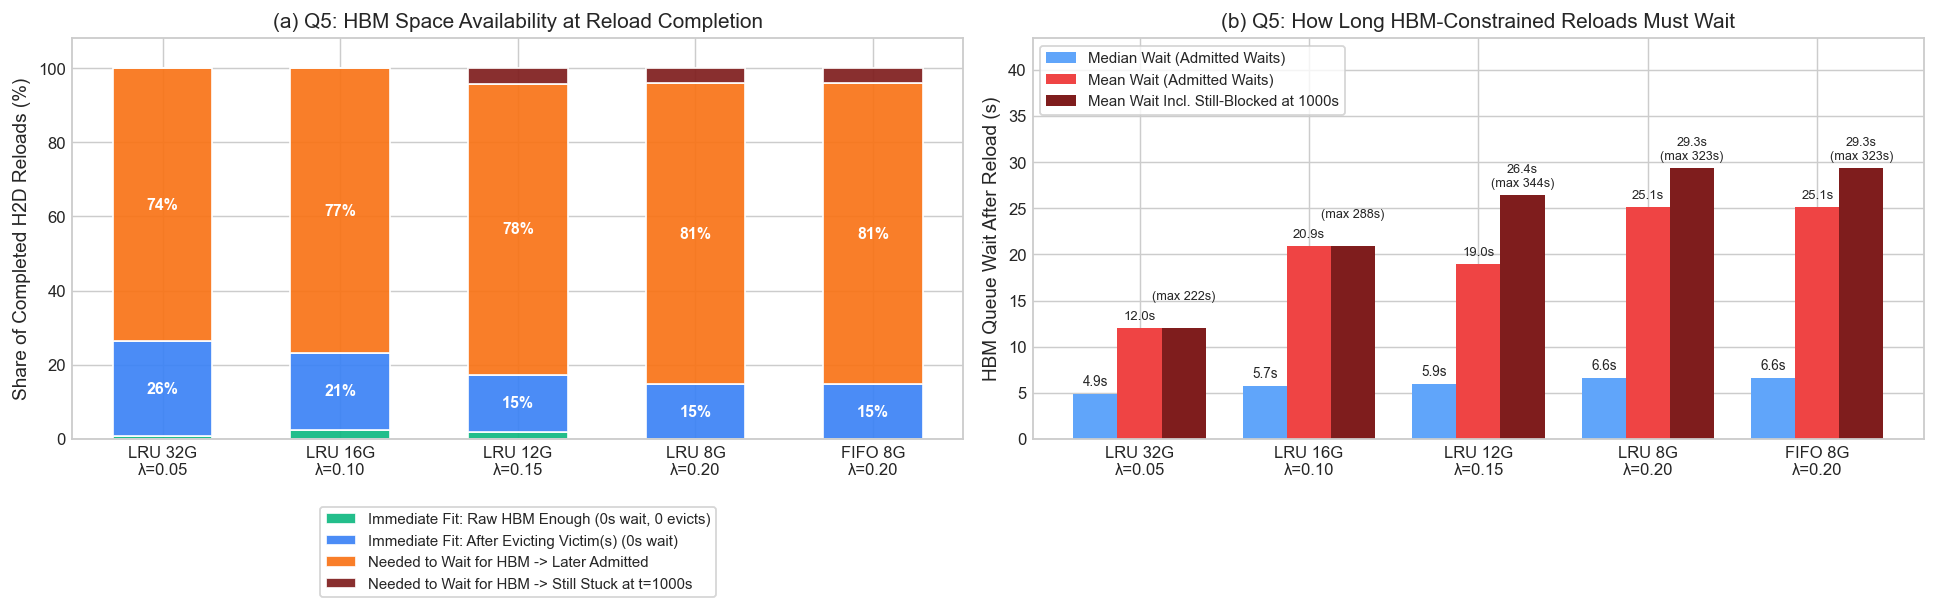

In [7]:
hdr = (
    f"{'Config (NoProact)':<18} | {'ReloadDone':<10} | {'Fit RawFree':<11} | {'Fit AfterEv':<11} | "
    f"{'WaitedHBM':<13} | {'WaitMean(Adm)':<13} | {'WaitP50(Adm)':<12} | {'WaitMax(Adm)':<12} | {'WaitMean(All+Cens)'}"
)
print(hdr)
print("-" * len(hdr))
for _, m in verify_runs:
    cfg = f"{m['policy'].upper()} {m['kv_hbm_gb']:.0f}G λ={m['rate']:.2f}"
    rd = m["reload_done_count"]
    w_tot = f"{m['reload_waited_for_hbm_count']} ({100*m['reload_waited_for_hbm_count']/max(1,rd):.1f}%)"
    print(f"{cfg:<18} | {rd:>10d} | {m['reload_fit_immediately_raw_no_evict']:>11d} | "
          f"{m['reload_fit_immediately_after_evict']:>11d} | {w_tot:<13} | "
          f"{m['reload_hbm_wait_mean_admitted_s']:>11.2f} s | "
          f"{m['reload_hbm_wait_p50_admitted_s']:>10.2f} s | "
          f"{m['reload_hbm_wait_max_admitted_s']:>10.1f} s | "
          f"{m['reload_hbm_wait_mean_all_including_censored_s']:>11.2f} s ({m['reload_still_waiting_at_end_count']} open)")

fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.9))

# Panel A: Reload HBM Availability Outcome (100% stacked over reload_done_count)
fit_raw_pct, fit_ev_pct, wait_adm_pct, wait_open_pct = [], [], [], []
for _, m in verify_runs:
    rd = max(1, m["reload_done_count"])
    fit_raw_pct.append(100.0 * m["reload_fit_immediately_raw_no_evict"] / rd)
    fit_ev_pct.append(100.0 * m["reload_fit_immediately_after_evict"] / rd)
    wait_adm_pct.append(100.0 * m["reload_waited_then_admitted_count"] / rd)
    wait_open_pct.append(100.0 * m["reload_still_waiting_at_end_count"] / rd)

q5_stacks = [
    ("Immediate Fit: Raw HBM Enough (0s wait, 0 evicts)", fit_raw_pct, "#10b981"),
    ("Immediate Fit: After Evicting Victim(s) (0s wait)", fit_ev_pct, "#3b82f6"),
    ("Needed to Wait for HBM -> Later Admitted", wait_adm_pct, "#f97316"),
    ("Needed to Wait for HBM -> Still Stuck at t=1000s", wait_open_pct, "#7f1d1d"),
]
bottom = np.zeros(len(verify_runs))
for lbl, vals, col in q5_stacks:
    arr = np.array(vals)
    axes[0].bar(x, arr, width=0.56, bottom=bottom, label=lbl, color=col, alpha=0.92, edgecolor="white")
    for xi, v, b in zip(x, arr, bottom):
        if v >= 7.0:
            axes[0].text(xi, b + v / 2.0, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8.8, fontweight="bold")
    bottom += arr
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0, 108)
axes[0].set_ylabel("Share of Completed H2D Reloads (%)")
axes[0].set_title("(a) Q5: HBM Space Availability at Reload Completion")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=True, fontsize=8.3)

# Panel B: HBM Wait Time Distribution for Waiting Reloads (Completed vs All incl. Censored)
w_mean_adm = [m["reload_hbm_wait_mean_admitted_s"] for _, m in verify_runs]
w_p50_adm = [m["reload_hbm_wait_p50_admitted_s"] for _, m in verify_runs]
w_mean_all = [m["reload_hbm_wait_mean_all_including_censored_s"] for _, m in verify_runs]
w_max_adm = [m["reload_hbm_wait_max_admitted_s"] for _, m in verify_runs]

w2 = 0.26
axes[1].bar(x - w2, w_p50_adm, w2, label="Median Wait (Admitted Waits)", color="#60a5fa")
axes[1].bar(x,      w_mean_adm, w2, label="Mean Wait (Admitted Waits)", color="#ef4444")
axes[1].bar(x + w2, w_mean_all, w2, label="Mean Wait Incl. Still-Blocked at 1000s", color="#7f1d1d")
for xi, p50, mn, mna, mx in zip(x, w_p50_adm, w_mean_adm, w_mean_all, w_max_adm):
    axes[1].text(xi - w2, p50 + 0.6, f"{p50:.1f}s", ha="center", va="bottom", fontsize=7.5)
    if abs(mna - mn) < 0.8:
        axes[1].text(xi,      mn + 0.6,  f"{mn:.1f}s", ha="center", va="bottom", fontsize=7.3)
        axes[1].text(xi + w2, mna + 2.8, f"(max {mx:.0f}s)", ha="center", va="bottom", fontsize=7.0)
    else:
        axes[1].text(xi,      mn + 0.6,  f"{mn:.1f}s", ha="center", va="bottom", fontsize=7.3)
        axes[1].text(xi + w2, mna + 0.6, f"{mna:.1f}s\n(max {mx:.0f}s)", ha="center", va="bottom", fontsize=7.0)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylim(0, max(w_mean_all + w_mean_adm) * 1.48)
axes[1].set_ylabel("HBM Queue Wait After Reload (s)")
axes[1].set_title("(b) Q5: How Long HBM-Constrained Reloads Must Wait")
axes[1].legend(loc="upper left", frameon=True, fontsize=8.3)

plt.tight_layout()
plt.show()

## 7. Temporal Dynamics (`12 GB LRU`) & Controlled Fixed-Load HBM Sweep ($\lambda = 0.20\text{ req/s}$)

To tie Q1–Q5 together:
- **Figure 6** plots the `12 GB LRU (NoProact)` run over time (`HBM` vs `DRAM`, session counts, PCIe queue wait spikes, and continuous time-weighted session states across all 5 configs).
- **Figure 7** holds the arrival process fixed at $\lambda = 0.20\text{ req/s}$ and sweeps `HBM = [8, 12, 16, 24, 32] GB` for `LRU` (plus `8, 12, 16 GB` `FIFO`).

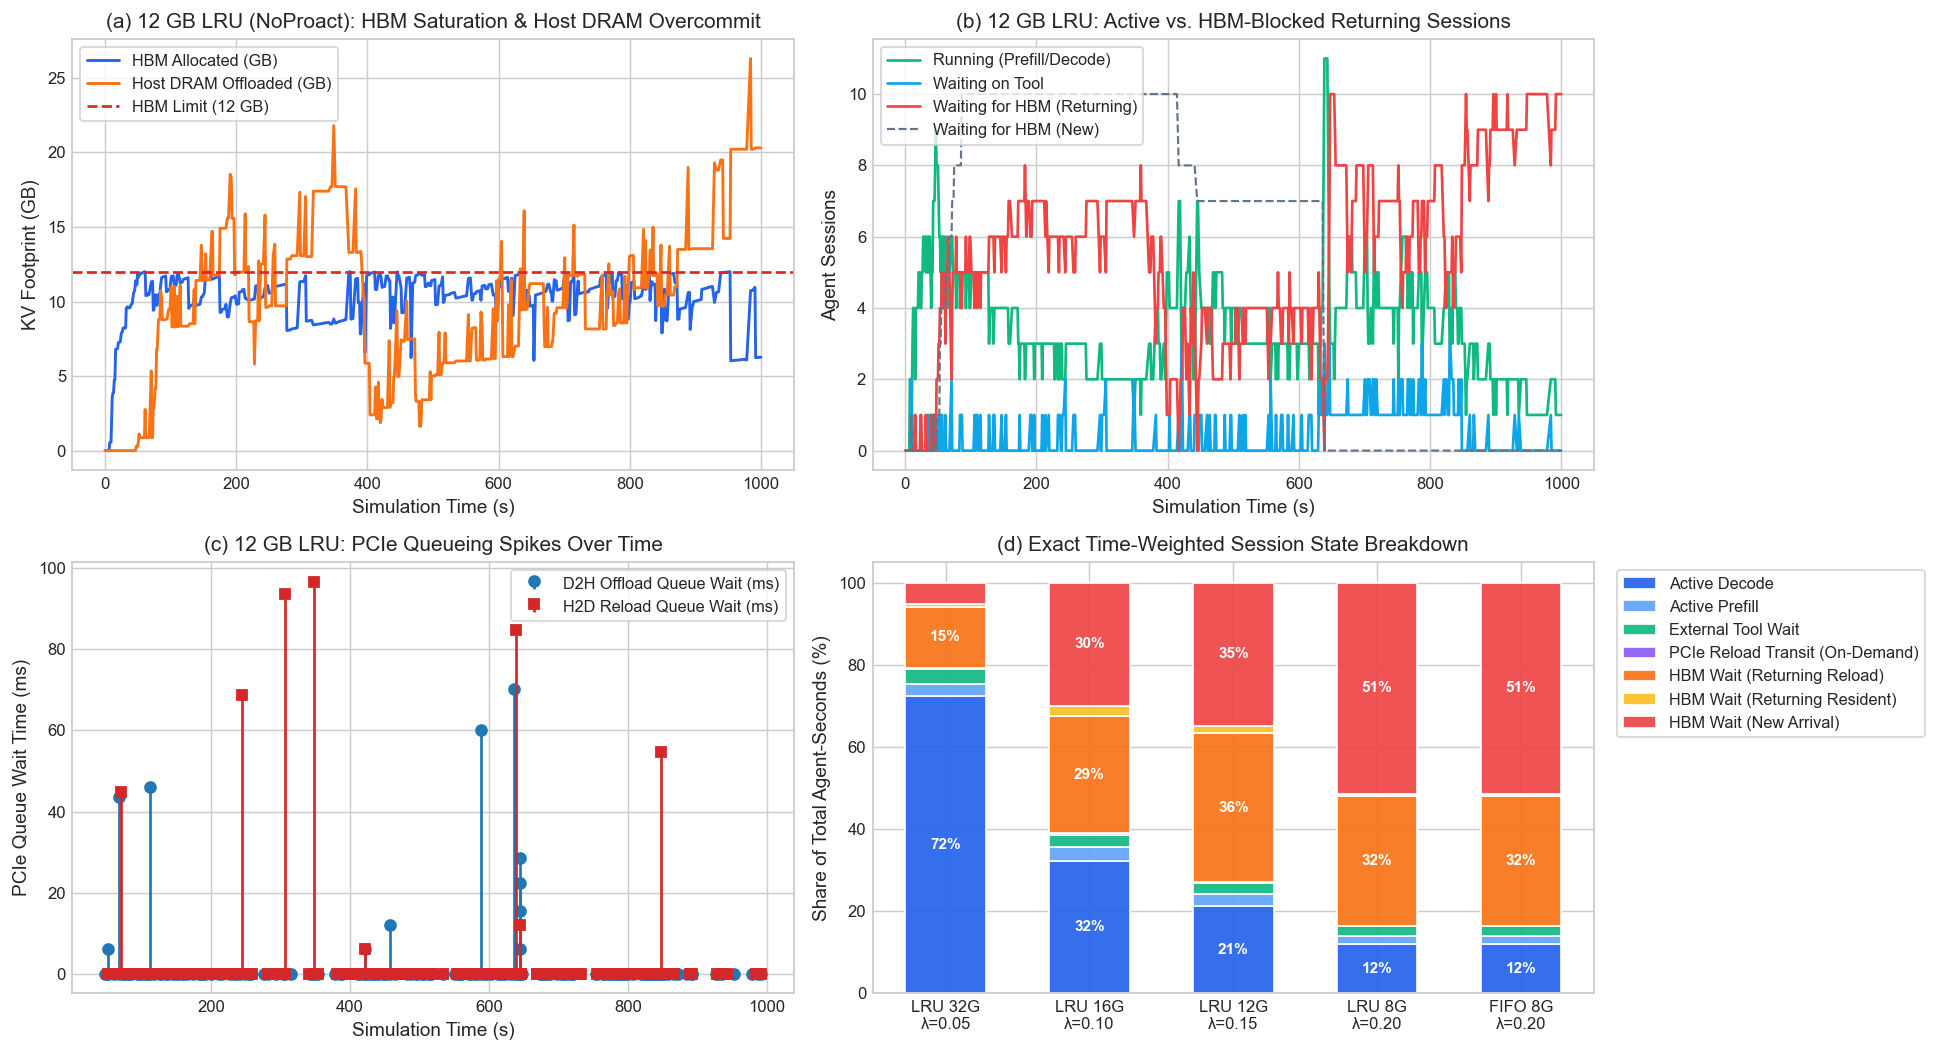

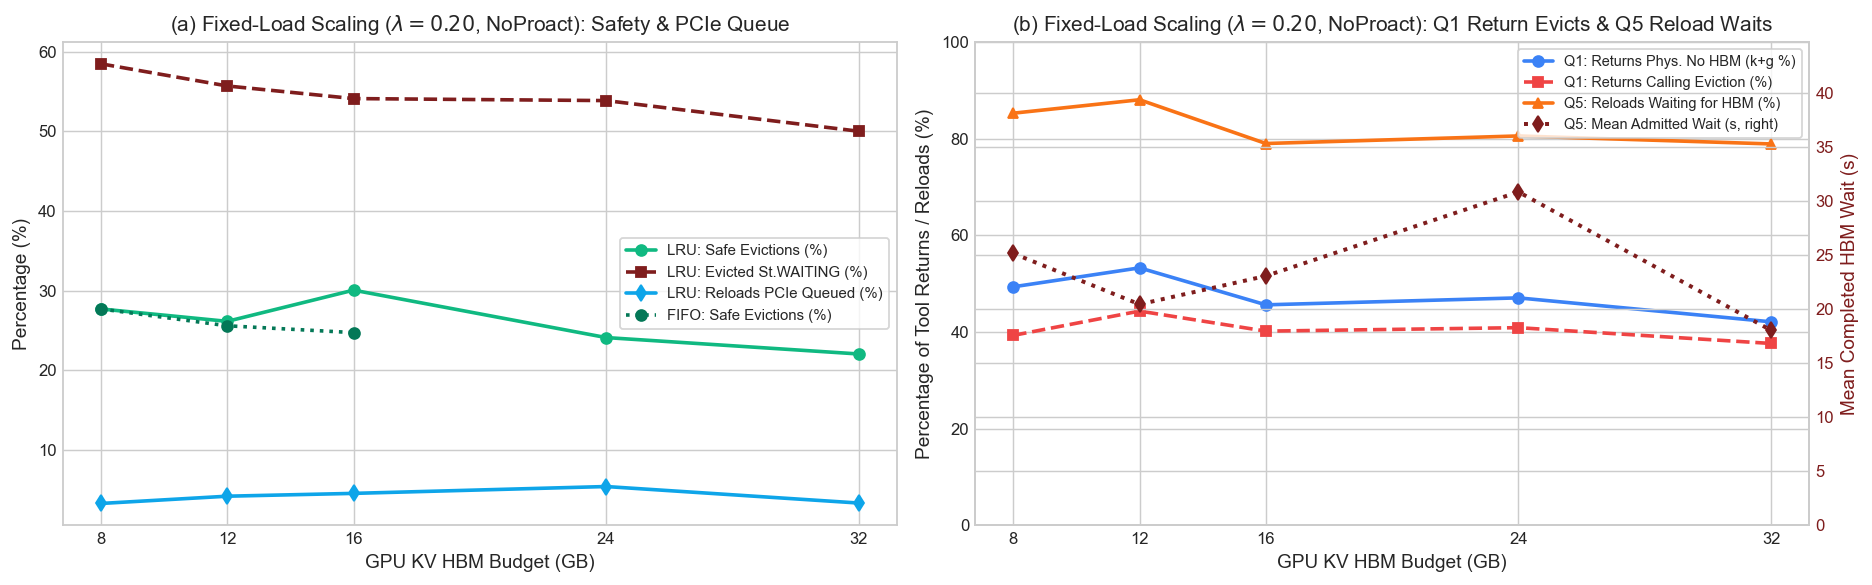

In [8]:
# Inspect 12 GB LRU timeline (index 2)
sim_12g, m_12g = verify_runs[2]
tl = sim_12g.timeline
ts = np.array([row["t"] for row in tl])
blk_gb = geom.bytes_per_block / (1024**3)
hbm_gb = np.array([row["alloc_blocks"] * blk_gb for row in tl])
dram_gb = np.array([row["dram_blocks"] * blk_gb for row in tl])

fig, axes = plt.subplots(2, 2, figsize=(15, 8.2))

ax = axes[0, 0]
ax.plot(ts, hbm_gb, color="#2563eb", lw=1.6, label="HBM Allocated (GB)")
ax.plot(ts, dram_gb, color="#f97316", lw=1.6, label="Host DRAM Offloaded (GB)")
ax.axhline(m_12g["kv_hbm_gb"], color="#dc2626", linestyle="--", lw=1.5, label=f"HBM Limit ({m_12g['kv_hbm_gb']:.0f} GB)")
ax.set_xlabel("Simulation Time (s)")
ax.set_ylabel("KV Footprint (GB)")
ax.set_title("(a) 12 GB LRU (NoProact): HBM Saturation & Host DRAM Overcommit")
ax.legend(loc="upper left", frameon=True)

ax = axes[0, 1]
ax.plot(ts, [r["dec"] + r["pre"] for r in tl], color="#10b981", lw=1.5, label="Running (Prefill/Decode)")
ax.plot(ts, [r["tool"] for r in tl], color="#0ea5e9", lw=1.5, label="Waiting on Tool")
ax.plot(ts, [r["ret_ev"] + r["ret_res"] for r in tl], color="#ef4444", lw=1.5, label="Waiting for HBM (Returning)")
ax.plot(ts, [r["new"] for r in tl], color="#64748b", lw=1.2, linestyle="--", label="Waiting for HBM (New)")
ax.set_xlabel("Simulation Time (s)")
ax.set_ylabel("Agent Sessions")
ax.set_title("(b) 12 GB LRU: Active vs. HBM-Blocked Returning Sessions")
ax.legend(loc="upper left", frameon=True)

ax = axes[1, 0]
ev_ts = [e["time"] for e in sim_12g.eviction_events]
ev_qw = [e["d2h_queue_wait_s"] * 1000 for e in sim_12g.eviction_events]
ret_ts = [r["return_time"] for r in sim_12g.return_events if r["was_evicted"]]
ret_qw = [r["pcie_h2d_queue_wait_s"] * 1000 for r in sim_12g.return_events if r["was_evicted"]]
ax.stem(ev_ts, ev_qw, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="D2H Offload Queue Wait (ms)")
ax.stem(ret_ts, ret_qw, linefmt="C3-", markerfmt="C3s", basefmt=" ", label="H2D Reload Queue Wait (ms)")
ax.set_xlabel("Simulation Time (s)")
ax.set_ylabel("PCIe Queue Wait Time (ms)")
ax.set_title("(c) 12 GB LRU: PCIe Queueing Spikes Over Time")
ax.legend(loc="upper right", frameon=True)

ax = axes[1, 1]
state_keys = [
    ("DECODE", "Active Decode", "#2563eb"),
    ("PREFILL", "Active Prefill", "#60a5fa"),
    ("TOOL", "External Tool Wait", "#10b981"),
    ("STALL", "PCIe Reload Transit (On-Demand)", "#8b5cf6"),
    ("WAITING_RET_EVICTED", "HBM Wait (Returning Reload)", "#f97316"),
    ("WAITING_RET_RESIDENT", "HBM Wait (Returning Resident)", "#fbbf24"),
    ("WAITING_NEW", "HBM Wait (New Arrival)", "#ef4444"),
]
bottom = np.zeros(len(verify_runs))
for key, lbl, col in state_keys:
    vals = np.array([m["state_pct"][key] for _, m in verify_runs])
    ax.bar(x, vals, width=0.56, bottom=bottom, label=lbl, color=col, alpha=0.92, edgecolor="white")
    for xi, v, b in zip(x, vals, bottom):
        if v >= 8.0:
            ax.text(xi, b + v / 2.0, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    bottom += vals
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Share of Total Agent-Seconds (%)")
ax.set_ylim(0, 105)
ax.set_title("(d) Exact Time-Weighted Session State Breakdown")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=True)

plt.tight_layout()
plt.show()

# Controlled Fixed-Load Sweep at lambda = 0.20 req/s (reusing 8G LRU and 8G FIFO from verify_runs)
lru_budgets = [8.0, 12.0, 16.0, 24.0, 32.0]
lru_sweep = [verify_runs[3]] + [run_instrumented(hbm, 0.20, "lru") for hbm in lru_budgets[1:]]
fifo_budgets = [8.0, 12.0, 16.0]
fifo_sweep = [verify_runs[4]] + [run_instrumented(hbm, 0.20, "fifo") for hbm in fifo_budgets[1:]]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
xs_l = np.array(lru_budgets)
xs_f = np.array(fifo_budgets)

axes[0].plot(xs_l, [m["safe_ideal_pct"] for _, m in lru_sweep], "o-", lw=2, color="#10b981", label="LRU: Safe Evictions (%)")
axes[0].plot(xs_l, [100*m["evicted_while_waiting_count"]/max(1,m["total_evictions"]) for _, m in lru_sweep], "s--", lw=2, color="#7f1d1d", label="LRU: Evicted St.WAITING (%)")
axes[0].plot(xs_l, [m["h2d_queue_waited_pct_of_reloads"] for _, m in lru_sweep], "d-", lw=2, color="#0ea5e9", label="LRU: Reloads PCIe Queued (%)")
axes[0].plot(xs_f, [m["safe_ideal_pct"] for _, m in fifo_sweep], "o:", lw=2, color="#047857", label="FIFO: Safe Evictions (%)")
axes[0].set_xlabel("GPU KV HBM Budget (GB)")
axes[0].set_ylabel("Percentage (%)")
axes[0].set_title(r"(a) Fixed-Load Scaling ($\lambda=0.20$, NoProact): Safety & PCIe Queue")
axes[0].set_xticks(xs_l)
axes[0].legend(loc="center right", frameon=True, fontsize=8.3)

l1 = axes[1].plot(xs_l, [100*m["all_returns_no_hbm_for_kg_at_tool_done"]/max(1,m["total_tool_returns"]) for _, m in lru_sweep], "o-", lw=2, color="#3b82f6", label="Q1: Returns Phys. No HBM (k+g %)")
l2 = axes[1].plot(xs_l, [100*m["all_returns_triggered_admit_evict"]/max(1,m["total_tool_returns"]) for _, m in lru_sweep], "s--", lw=2, color="#ef4444", label="Q1: Returns Calling Eviction (%)")
l3 = axes[1].plot(xs_l, [100*m["reload_waited_for_hbm_count"]/max(1,m["reload_done_count"]) for _, m in lru_sweep], "^-", lw=2, color="#f97316", label="Q5: Reloads Waiting for HBM (%)")
axes[1].set_xlabel("GPU KV HBM Budget (GB)")
axes[1].set_ylabel("Percentage of Tool Returns / Reloads (%)")
axes[1].set_ylim(0, 100)
axes[1].set_title(r"(b) Fixed-Load Scaling ($\lambda=0.20$, NoProact): Q1 Return Evicts & Q5 Reload Waits")
axes[1].set_xticks(xs_l)

ax1_r = axes[1].twinx()
l4 = ax1_r.plot(xs_l, [m["reload_hbm_wait_mean_admitted_s"] for _, m in lru_sweep], "d:", lw=2.2, color="#7f1d1d", label="Q5: Mean Admitted Wait (s, right)")
ax1_r.set_ylabel("Mean Completed HBM Wait (s)", color="#7f1d1d")
ax1_r.tick_params(axis="y", labelcolor="#7f1d1d")
ax1_r.set_ylim(0, max(m["reload_hbm_wait_mean_admitted_s"] for _, m in lru_sweep) * 1.45)

lines = l1 + l2 + l3 + l4
axes[1].legend(lines, [l.get_label() for l in lines], loc="upper right", frameon=True, fontsize=8.0)

plt.tight_layout()
plt.show()

## 8. Leadership Briefing: Why Evictions Cascade & Why HBM Stalls Dominate

### 30-Second Executive Takeaways
1. **PCIe bandwidth is NOT the bottleneck — HBM admission queueing is `188×–432×` larger:**
   With `Proactive Reload = False` (on-demand only), evicted KV transfers over PCIe take only **`58–66 ms`** on average (`0.7–2.9 ms` queueing, `<5%` bus contention). Once loaded onto HBM queues, however, **`74%–85%` of reloads still wait `12.0–25.1 seconds` (median `4.9–6.6 s`, max `222–344 s`)** for GPU memory space — dragging active GPU decode down to **`9%–32%`** of session time at `8–16 GB`.
2. **One small resident shortage sparks a self-sustaining reload cascade (`1 -> 130–175` evictions):**
   Every run starts cleanly until cumulative multi-turn KV saturates HBM and **one resident turn (`admission_ret_resident` or 1-block `decode_growth`) triggers Eviction #1**. Because baseline evicts an **entire conversation (`0.3–4.1 GB`)** rather than just the needed pages while greedily letting other traffic consume the freed space, that evicted victim returns seconds later as a multi-gigabyte debt and triggers **`73%–79%` of all future evictions**.
3. **Two policy flaws amplify the damage:**
   - **Evicting `St.WAITING` sessions (`50%–59%` of all victims):** LRU/FIFO evict sessions whose tool calls have *already finished* (`Δt = 0`), forcing immediate reload bounce-backs and leaving only **`25%–28%`** of evictions safe (`Δt >= T_RTT`).
   - **Coarse whole-conversation allocation/eviction:** Individual SWE-bench trajectories reach `10.8–24.4 GB` alone; evicting and reloading them atomically starves HBM at `8–16 GB` budgets.

**Figure 8** illustrates both the exact first-40-second domino cascade (`LRU 32 GB`) and the two-orders-of-magnitude gap between PCIe stall and HBM queue blocking.

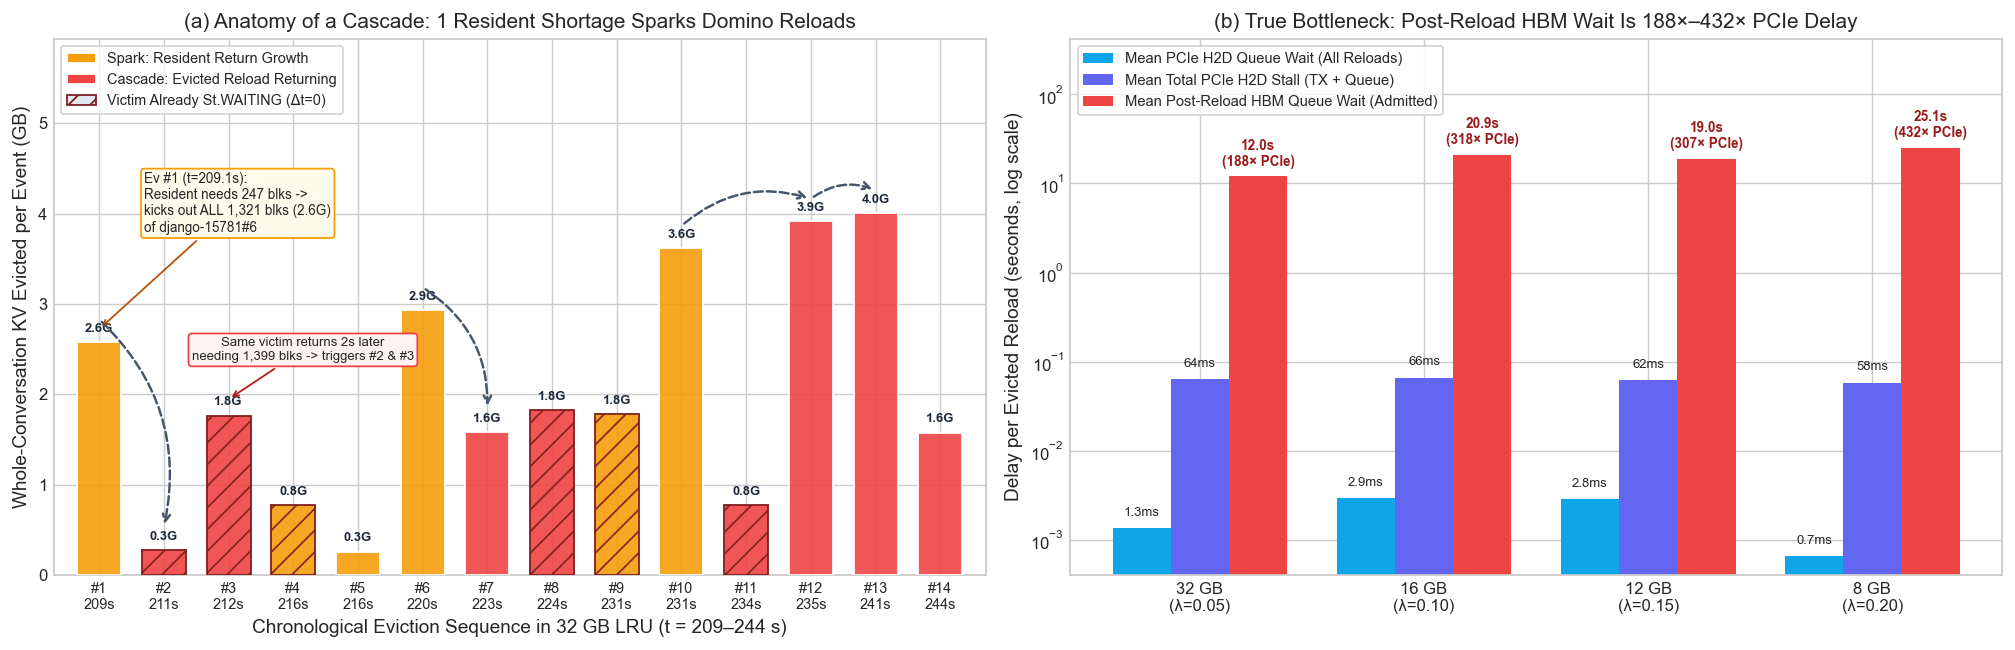

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15.6, 5.1))

# Panel A: First 14 evictions in 32 GB LRU showing Resident Spark -> Evicted Reload Cascade
sim_32, _ = verify_runs[0]
win_evs = sim_32.eviction_events[:14]
blk_gb = geom.bytes_per_block / (1024**3)
xc = np.arange(len(win_evs))
t_evs = np.array([e["time"] for e in win_evs])
gb_evs = np.array([e["blocks"] * blk_gb for e in win_evs])
is_reload_trig = [e["trigger_detail"] == "admission_ret_evicted" for e in win_evs]
is_wait_vic = [e["victim_state"] == "waiting" for e in win_evs]

# Plot evenly spaced domino bars (prevents identical-timestamp overlap) with exact timestamp tick labels
for i, (gbe, is_rel, is_wt) in enumerate(zip(gb_evs, is_reload_trig, is_wait_vic)):
    col = "#ef4444" if is_rel else "#f59e0b"
    edge = "#7f1d1d" if is_wt else "white"
    hatch = "//" if is_wt else None
    axes[0].bar(i, gbe, width=0.68, color=col, edgecolor=edge, linewidth=1.1, hatch=hatch, alpha=0.9, zorder=3)
    axes[0].text(i, gbe + 0.08, f"{gbe:.1f}G", ha="center", va="bottom", fontsize=7.2, fontweight="bold", color="#1e293b")

# Legend proxies for Panel A
from matplotlib.patches import Patch
axes[0].legend(
    handles=[
        Patch(facecolor="#f59e0b", edgecolor="white", label="Spark: Resident Return Growth"),
        Patch(facecolor="#ef4444", edgecolor="white", label="Cascade: Evicted Reload Returning"),
        Patch(facecolor="#e2e8f0", edgecolor="#7f1d1d", hatch="//", label="Victim Already St.WAITING (Δt=0)"),
    ],
    loc="upper left", frameon=True, fontsize=8.0,
)

# Draw causal links where Victim_i returns as Evicted Requester_j in the cascade
seen_links = []
for j, ej in enumerate(win_evs):
    if ej["trigger_detail"] != "admission_ret_evicted":
        continue
    for i in range(j - 1, -1, -1):
        if win_evs[i]["victim_id"] == ej["requester_id"]:
            seen_links.append((i, j))
            break

for idx_i, idx_j in seen_links:
    if (idx_i, idx_j) in {(0, 1), (5, 6), (9, 11), (11, 12)}:
        axes[0].annotate(
            "",
            xy=(idx_j, gb_evs[idx_j] + 0.25),
            xytext=(idx_i, gb_evs[idx_i] + 0.25),
            arrowprops=dict(arrowstyle="->", color="#475569", lw=1.35, connectionstyle="arc3,rad=-0.28", ls="--"),
            zorder=4,
        )

axes[0].annotate(
    "Ev #1 (t=209.1s):\nResident needs 247 blks ->\nkicks out ALL 1,321 blks (2.6G)\nof django-15781#6",
    xy=(0, gb_evs[0] + 0.14),
    xytext=(0.7, 3.80),
    fontsize=7.5, bbox=dict(boxstyle="round,pad=0.25", fc="#fffbeb", ec="#f59e0b", lw=1),
    arrowprops=dict(arrowstyle="->", color="#b45309", lw=1.0),
)
axes[0].annotate(
    "Same victim returns 2s later\nneeding 1,399 blks -> triggers #2 & #3",
    xy=(2.0, gb_evs[2] + 0.18),
    xytext=(3.15, 2.38),
    ha="center",
    fontsize=7.3, bbox=dict(boxstyle="round,pad=0.25", fc="#fef2f2", ec="#ef4444", lw=1),
    arrowprops=dict(arrowstyle="->", color="#b91c1c", lw=1.0),
)

axes[0].set_xticks(xc)
axes[0].set_xticklabels([f"#{i+1}\n{te:.0f}s" for i, te in enumerate(t_evs)], fontsize=8.0)
axes[0].set_xlim(-0.7, len(win_evs) - 0.3)
axes[0].set_ylim(0, max(gb_evs) * 1.48)
axes[0].set_xlabel("Chronological Eviction Sequence in 32 GB LRU (t = 209–244 s)")
axes[0].set_ylabel("Whole-Conversation KV Evicted per Event (GB)")
axes[0].set_title("(a) Anatomy of a Cascade: 1 Resident Shortage Sparks Domino Reloads")

# Panel B: Log-scale Delay Comparison (PCIe Queue vs PCIe Total Stall vs HBM Wait)
lru_only = verify_runs[:4]
xb = np.arange(len(lru_only))
x_lbls = [f"{m['kv_hbm_gb']:.0f} GB\n(λ={m['rate']:.2f})" for _, m in lru_only]
pcie_q_s = np.array([max(1e-4, m["mean_h2d_queue_wait_s"]) for _, m in lru_only])
pcie_tot_s = np.array([m["mean_h2d_total_pcie_wait_s"] for _, m in lru_only])
hbm_wait_s = np.array([m["reload_hbm_wait_mean_admitted_s"] for _, m in lru_only])

wb = 0.26
axes[1].bar(xb - wb, pcie_q_s, wb, label="Mean PCIe H2D Queue Wait (All Reloads)", color="#0ea5e9")
axes[1].bar(xb,      pcie_tot_s, wb, label="Mean Total PCIe H2D Stall (TX + Queue)", color="#6366f1")
axes[1].bar(xb + wb, hbm_wait_s, wb, label="Mean Post-Reload HBM Queue Wait (Admitted)", color="#ef4444")

for i, (pq, pt, hw) in enumerate(zip(pcie_q_s, pcie_tot_s, hbm_wait_s)):
    ratio = hw / pt
    axes[1].text(i - wb, pq * 1.28, f"{pq*1000:.1f}ms", ha="center", va="bottom", fontsize=7.3)
    axes[1].text(i,      pt * 1.28, f"{pt*1000:.0f}ms", ha="center", va="bottom", fontsize=7.3)
    axes[1].text(i + wb, hw * 1.22, f"{hw:.1f}s\n({ratio:.0f}× PCIe)", ha="center", va="bottom", fontsize=7.5, fontweight="bold", color="#991b1b")

axes[1].set_yscale("log")
axes[1].set_ylim(4e-4, 420.0)
axes[1].set_xticks(xb)
axes[1].set_xticklabels(x_lbls)
axes[1].set_ylabel("Delay per Evicted Reload (seconds, log scale)")
axes[1].set_title("(b) True Bottleneck: Post-Reload HBM Wait Is 188×–432× PCIe Delay")
axes[1].legend(loc="upper left", frameon=True, fontsize=8.2)

plt.tight_layout()
plt.show()

## 9. Complete Metrics Summary & Actionable Roadmap for Leadership

### Complete Question-by-Question Characterization (`LRU` / `FIFO`, `Proactive Reload = False`, Fixed Incremental Admission)

1. **Q1 — Returning tool calls lacking HBM & triggering eviction:**
   - **Resident returns** physically lack HBM for new tokens $k$ at `tool_done` only **5%–7%** of the time (`12/250` at `32 GB`, `7/107` at `8 GB`), yet **13%–20%** still trigger eviction when admitted because `tool_done` for resident requests waits up to `0.5s` for the next `epoch` tick while decodes/reloads consume free space.
   - **Evicted returns** must bring back their entire prior context + $k$, lacking raw HBM **81%–88%** of the time. Combined across all returns, **33%–50%** physically lack HBM at `tool_done` and **29%–42%** call `_force_unpin`.
2. **Q2 — Total & per-return evictions:**
   - Across **`130–175` total evictions** per check-test run (`0.37–0.59` overall evictions/return), **`96%–99%` happen inside `_admit_full` for returning tool calls**: **`73%–79%`** driven by evicted reloads and **`17%–25%`** by resident growth (`0–1` Turn-0 new arrivals, `0–2` decode growth).
   - Because each whole-conversation eviction frees `~0.3–4.1 GB` at once, returning calls that trigger eviction average only **`1.23–1.39` evictions** (`0.36–0.57` causal admit evictions over all returns).
3. **Q3 — Safe vs. Unsafe evictions:**
   - Only **`24.6%–27.7%`** of evictions are **safe** ($\Delta t \ge T_{\text{RTT}}$) — **`72.3%–75.4%` are unsafe**.
   - Over half (**`50.3%–58.5%`**) evict sessions **already in `St.WAITING` ($\Delta t = 0$)** because `_force_unpin` treats parked `St.WAITING` sessions alongside active `St.TOOL` sessions. Among `St.TOOL`-only victims, **`54.4%–66.7%`** are safe.
4. **Q4 — PCIe bus wait on reloads (`Proactive Reload = False`):**
   - **100%** of evicted reloads wait for PCIe H2D serialization TX (**`57.6–62.8 ms`** mean).
   - **Only `2.2%–4.9%`** face **PCIe H2D FIFO queueing** behind another reload (**`19.9–67.5 ms`** mean when queued, max **`143 ms`**; **`0.7–2.9 ms`** amortized across all reloads); **`1.6%–5.8%`** return before D2H offload even finished.
5. **Q5 — HBM space on reload completion & wait times:**
   - Only **`0%–2.5%`** of finished reloads fit from already-free HBM without evicting; **`14.8%–25.5%`** fit only after evicting another victim (`0s` wait); and **`73.7%–85.2%` MUST WAIT in `St.WAITING` for HBM**.
   - Admitted waits average **`12.0–25.1 s`** (median **`4.9–6.6 s`**, max **`222–344 s`**), with `5–7` oversized/head-blocked sessions still stalled at `t = 1000s` under `8–12 GB`.

### What This Means for Policy & Architecture Design

| Measured Pathology in Current Baseline | Impact Observed | Recommended Change / Ablation |
| :--- | :--- | :--- |
| **`St.WAITING` sessions evicted first (`50%–59%` of evictions)** | Evicts already-finished calls -> instant `1,000+` blk reload bounce-backs; only `25%–28%` safe evictions. | Exclude `St.WAITING` from `_force_unpin` candidates; prioritize victims with largest positive slack ($\Delta t - T_{\text{RTT}}$). |
| **All-or-nothing conversation eviction (`0.3–4.1 GB` per victim)** | A small `114–677` blk resident shortage creates a `1,300+` blk reload debt -> `73%–79%` reload cascade; >`8 GB` trajectories deadlock. | **Paged / chunked eviction** (evict just enough tail KV blocks to cover the deficit, keeping hot prefixes & letting oversized sessions make progress). |
| **Unreserved freed HBM & greedy Turn-0 / HBM-blind reload** | Freed space gets absorbed before evicted sessions return -> `74%–85%` of reloads stall `12–25 s` after PCIe finishes. | **HBM-aware admission & reload coordination** (reserve headroom or coordinate proactive H2D only when HBM blocks are actually secured). |
| **Optimistic zero-queue PCIe assumption in candidate selection** | Ignores D2H/H2D serialization contention spikes (up to `143 ms` queue wait) under bursty / large conversations. | Add **queue-aware PCIe RTT estimation** and run conversation-size ablations (few large vs. many small conversations at fixed byte/s load). |